# Буткемп, электронный relative-value трейдинг, день 18 — event-driven backtest и bias control

Пишем движок, который физически не может подсмотреть будущее: одна очередь событий, три часа (replay / strategy / exchange), латентности как распределения, отдельные часы для market data, решения, входа, ack, отмены и отчёта о филле. Стратегия не получает ссылку на replay или на книгу биржи — только событие и `now`.

Проверки — там, где нет «правильного ответа»:
1. **Garbage test** — портим все данные после трёх разных $T$ и требуем бит-в-бит совпадения всего, что произошло до $T$.
2. **Null-strategy test** — случайные входы без сигнала; движок должен потерять ровно cost stack, предсказанный днём 17, и ни тиком больше.
3. **Latency sweep** — PnL не может расти с латентностью; растёт — значит в движке баг.
4. **Bias waterfall** — восемь шагов от векторного бэктеста к полностью смоделированному.
5. **Optimism ledger** — каждая оптимистичная предпосылка с направлением и планом.

Инструмент прежний: BTCUSDT на Bybit, 100-мс top-of-book и трейды, окно 2026-07-01 12:00–12:30 UTC. Тик $0.1$.

## Данные и признаки

Книга — top-of-book: bid/ask и размеры на touch. Трейды размечаем по стороне агрессора: цена у ask — buy, у bid — sell. Изменение глубины, которое не объясняется трейдами, считаем отменами впереди; это вход в cancel convention. Все ряды лежат в numpy-массивах, время — наносекунды.

In [1]:
import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt, heapq, math, hashlib, json, warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width',180); pd.set_option('display.max_columns',40)

D='/Users/b.kotov/Downloads/'
Q=D+'l2_executable_quotes_100ms_10000.parquet'
T0='2026-07-01 12:00:00+00'; T1='2026-07-01 12:30:00+00'
con=duckdb.connect()
panel=con.execute(f"""SELECT event_time, mid, best_bid, best_ask, best_bid_amount, best_ask_amount
 FROM read_parquet('{Q}') WHERE asset='BTC' AND exchange='Bybit'
 AND event_time>=TIMESTAMPTZ '{T0}' AND event_time<TIMESTAMPTZ '{T1}' ORDER BY event_time""").df().reset_index(drop=True)
tr=con.execute(f"""SELECT event_time, price, amount FROM read_parquet('{D}bybit_anon_trades_20260701_20260703.parquet')
 WHERE symbol='BTCUSDT' AND event_time>=TIMESTAMPTZ '{T0}' AND event_time<TIMESTAMPTZ '{T1}' ORDER BY event_time""").df()
tick=0.1; n=len(panel)
T=np.array(panel.event_time.astype('int64'))
mid=panel.mid.values; bid=panel.best_bid.values; ask=panel.best_ask.values
bsz=panel.best_bid_amount.values; asz=panel.best_ask_amount.values
tt=np.array(tr.event_time.astype('int64'))
idx=np.searchsorted(T,tt,'right')-1
ok=(idx>=0)&(idx<n); keep=np.where(ok)[0]; idx=idx[keep]; tt=tt[keep]; tr=tr.iloc[keep].reset_index(drop=True)
px=tr.price.values; amt=tr.amount.values
is_buy=np.abs(px-ask[idx])<=tick/2; is_sell=np.abs(px-bid[idx])<=tick/2
tdir=np.where(is_buy,1,np.where(is_sell,-1,0))
tbv=np.zeros(n); tav=np.zeros(n)
for j in np.where(is_sell)[0]: tbv[idx[j]]+=amt[j]
for j in np.where(is_buy)[0]: tav[idx[j]]+=amt[j]
db=np.maximum(-np.diff(bsz,prepend=bsz[0]),0); da=np.maximum(-np.diff(asz,prepend=asz[0]),0)
cb=np.maximum(db-tbv,0); ca=np.maximum(da-tav,0)
NS=1_000_000_000
MID_MEAN=float(np.mean(mid))
print('строк %d, трейдов %d; отмен впереди по прокси: bid %.0f, ask %.0f BTC' % (n,len(tr),cb.sum(),ca.sum()))

строк 17233, трейдов 66466; отмен впереди по прокси: bid 4072, ask 4777 BTC


## Движок

Очередь с ключом `(ts_ns, seq, kind)`. События — только в будущее: `sched` сдвигает попытку записать событие в прошлое на `now+1`. Биржа обновляет книгу в момент replay-события, стратегия видит **строку $i$**, а не текущую книгу биржи; ордер получает приоритет в момент прихода на биржу. Сделки сначала съедают очередь впереди, потом заполняют нас. FILL приходит стратегии с задержкой отчёта.

Активных латентностей пять: market data, decision + order entry, cancel и fill report. Каждая — lognormal с медианой из конфига и джиттером, сид фиксирован. `mult` масштабирует все. Ack в этой реализации ни на что не влияет, поэтому отдельного шага нет.

In [2]:
class Cfg(dict):
    def __getattr__(self,k): return self[k]
    def __setattr__(self,k,v): self[k]=v

def draw(rng,base,mult):
    if mult<=0: return 0
    return int(rng.lognormal(math.log(max(base*mult,1)),0.35))

class MM:
    "Пассивный маркет-мейкер: каждые 5 с снимает старые котировки и ставит новые на touch."
    def __init__(self,eng,age=5.0,qty=1.0,bad_lookahead=False,global_mid=None):
        self.e=eng; self.qty=qty; self.live=[]; self.bad=bad_lookahead; self.gmid=global_mid
    def on_data(self,now,i,book):
        if i%50: return
        shift_ticks=int(round((self.gmid-book['mid'])/tick*0.1)) if (self.bad and self.gmid is not None) else 0
        for oid in self.live: self.e.send_cancel(oid,now)
        self.live=[]
        b=self.e.send_order('B',round((book['bid']+shift_ticks*tick)/tick)*tick,self.qty,now,passive=True)
        a=self.e.send_order('S',round((book['ask']+shift_ticks*tick)/tick)*tick,self.qty,now,passive=True)
        if b: self.live.append(b)
        if a: self.live.append(a)
    def on_fill_known(self,now,p): pass

class Mom:
    "Latency-sensitive taker: каждые 5 с входит по знаку 1-секундного возврата, держит 5 с, выходит."
    def __init__(self,eng,H=10):
        self.e=eng; self.H=H; self.hist=[]; self.nsig=0
    def on_data(self,now,i,book):
        self.hist.append(book['mid'])
        if len(self.hist)<12 or i%50: return
        sig=(book['mid']-self.hist[-11])/tick
        self.nsig+=1
        self.e.send_aggressive(1 if sig>=0 else -1,1.0,now,tag='mom')
    def on_aggr_fill(self,now,side,price,qty,tag):
        if tag!='exit': self.e.sched(now+int(self.H*0.1*NS),'TIMER',{'side':side,'entry':price,'qty':qty,'tag':'exit'})
    def on_timer(self,now,p):
        if p.get('tag')=='exit': self.e.send_aggressive(-p['side'],p['qty'],now,tag='exit')

class NullAgg:
    "Null strategy: случайная сторона, вход каждые 5 с, горизонт 1 с."
    def __init__(self,eng,H=10,seed=3):
        self.e=eng; self.H=H; self.rng=np.random.default_rng(seed); self.n=0
    def on_data(self,now,i,book):
        if i%50: return
        side=1 if self.rng.random()<0.5 else -1; self.n+=1
        self.e.send_aggressive(side,1.0,now,tag='null')
    def on_aggr_fill(self,now,side,price,qty,tag):
        if tag!='exit': self.e.sched(now+int(self.H*0.1*NS),'TIMER',{'side':side,'entry':price,'qty':qty,'tag':'exit'})
    def on_timer(self,now,p):
        if p.get('tag')=='exit': self.e.send_aggressive(-p['side'],p['qty'],now,tag='exit')

class Engine:
    def __init__(self,cfg,strat,seed=7):
        self.cfg=cfg; self.strat=strat; self.rng=np.random.default_rng(seed); self.seq=0
        self.q=[]; self.now=0; self.book=None; self.pending={}; self.next_oid=1
        self.log=[]; self.fills=[]; self.rejects=0; self.cash=0.0; self.inv=0.0; self.fee=0.0
        self.aggr=[]; self.equity=[]
    def sched(self,ts,kind,p):
        ts=int(ts)
        if ts<self.now: ts=self.now+1
        self.seq+=1; heapq.heappush(self.q,(ts,self.seq,kind,p))
    def lat(self,base): return draw(self.rng,base,self.cfg.mult) if self.cfg.use_latency else 0
    def send_order(self,side,price,qty,now,passive=True):
        if abs(price/tick-round(price/tick))>1e-9: self.rejects+=1; return None
        if self.cfg.reject_prob and self.rng.random()<self.cfg.reject_prob: self.rejects+=1; return None
        ts=now+self.lat(10_000_000)+self.lat(20_000_000)
        oid=self.next_oid; self.next_oid+=1
        self.sched(ts,'ORDER',{'oid':oid,'side':side,'price':round(price,2),'qty':qty,'passive':passive})
        return oid
    def send_cancel(self,oid,now):
        o=self.pending.get(oid)
        if not o or o.get('cancelling'): return
        o['cancelling']=True
        self.sched(now+(self.lat(20_000_000) if self.cfg.use_cancel_latency else 0),'CANCEL',{'oid':oid})
    def send_aggressive(self,side,qty,now,tag=''):
        self.sched(now+self.lat(100_000)+self.lat(200_000),'AGGR',{'side':side,'qty':qty,'tag':tag})
    def emit_fill(self,oid,qty,price,now):
        o=self.pending[oid]; o['qty']-=qty
        self.fills.append({'t':now,'oid':oid,'side':o['side'],'price':price,'qty':qty})
        if o['qty']<=1e-9: del self.pending[oid]
        self.sched(now+self.lat(5_000_000),'FILL',{'oid':oid,'side':o['side'],'price':price,'qty':qty})
    def match_nq(self,price,now):
        for oid,o in list(self.pending.items()):
            cur_bid=bid[self.book['i']]; cur_ask=ask[self.book['i']]
            want='B' if abs(price-cur_bid)<=1e-9 else ('S' if abs(price-cur_ask)<=1e-9 else None)
            if want is not None and o['side']==want and abs(price-o['price'])<=1e-9:
                self.emit_fill(oid,o['qty'],o['price'],now)
    def match(self,price,amount,now):
        for oid,o in list(self.pending.items()):
            cur_bid=bid[self.book['i']]; cur_ask=ask[self.book['i']]
            want='B' if abs(price-cur_bid)<=1e-9 else ('S' if abs(price-cur_ask)<=1e-9 else None)
            if want is None or o['side']!=want or abs(price-o['price'])>1e-9: continue
            c=min(amount,o['queue']); o['queue']=max(0.0,o['queue']-c); amount-=c
            if amount>0 and o['queue']<=1e-9:
                f=min(amount,o['qty']); self.emit_fill(oid,f,o['price'],now); amount-=f
    def fill_aggr(self,now,side,qty,tag):
        price=ask[self.book['i']] if side==1 else bid[self.book['i']]
        self.cash-=side*price*qty; self.inv+=side*qty
        self.fee+=self.cfg.taker_bp*1e-4*MID_MEAN/tick*qty
        self.aggr.append({'t':now,'side':side,'price':price,'qty':qty,'tag':tag})
        if hasattr(self.strat,'on_aggr_fill'): self.strat.on_aggr_fill(now,side,price,qty,tag)
    def run(self):
        for i in range(n):
            self.sched(T[i],'MD_EX',{'i':i}); self.sched(T[i]+self.lat(30_000_000),'MD_STRAT',{'i':i})
        for j in range(len(px)): self.sched(tt[j],'TRADE',{'price':px[j],'amount':amt[j]})
        self.now=T[0]-1
        while self.q:
            ts,seq,kind,p=heapq.heappop(self.q)
            if ts<self.now: raise RuntimeError('time paradox')
            self.now=ts; self.log.append((ts,kind,str(p)[:140]))
            if kind=='MD_EX':
                i=p['i']; self.book={'i':i,'mid':mid[i],'bid':bid[i],'ask':ask[i],'bsz':bsz[i],'asz':asz[i]}
                if self.cfg.use_queue:
                    for oid,o in list(self.pending.items()):
                        cv=(cb[i] if o['side']=='B' else ca[i])*self.cfg.ahead_frac
                        if cv>0: o['queue']=max(0.0,o['queue']-cv)
                self.equity.append((ts,(self.cash+self.inv*mid[i])/tick-self.fee))
            elif kind=='TRADE':
                if self.cfg.use_queue: self.match(p['price'],p['amount'],ts)
                else: self.match_nq(p['price'],ts)
            elif kind=='MD_STRAT':
                i=p['i']; self.strat.on_data(ts,i,{'i':i,'mid':mid[i],'bid':bid[i],'ask':ask[i]})
            elif kind=='ORDER':
                price=p['price']; side=p['side']
                if p['passive']:
                    if abs(price/tick-round(price/tick))>1e-9: self.rejects+=1; continue
                    if side=='B' and price>self.book['bid']+1e-9: self.rejects+=1; continue
                    if side=='S' and price<self.book['ask']-1e-9: self.rejects+=1; continue
                    q=self.book['bsz'] if side=='B' else self.book['asz']
                    self.pending[p['oid']]={'side':side,'price':price,'qty':p['qty'],'queue':q}
                else: self.fill_aggr(ts,side,p['qty'],p.get('tag',''))
            elif kind=='AGGR': self.fill_aggr(ts,p['side'],p['qty'],p.get('tag',''))
            elif kind=='CANCEL': self.pending.pop(p['oid'],None)
            elif kind=='FILL':
                if hasattr(self.strat,'on_fill_known'): self.strat.on_fill_known(ts,p)
                sgn=1 if p['side']=='B' else -1
                self.cash-=sgn*p['price']*p['qty']; self.inv+=sgn*p['qty']
                self.fee+=self.cfg.maker_bp*1e-4*MID_MEAN/tick*p['qty']
            elif kind=='TIMER':
                if hasattr(self.strat,'on_timer'): self.strat.on_timer(ts,p)
        mtm=(self.cash+self.inv*mid[-1])/tick
        return {'mtm':mtm,'fee':self.fee,'net':mtm-self.fee,
                'fills':len(self.fills),'rejects':self.rejects,'pending':len(self.pending)}

BASE=dict(use_latency=True,mult=1.0,use_queue=True,ahead_frac=0.5,use_cancel_latency=True,
          reject_prob=0.0,maker_bp=0.0,taker_bp=2.0)
def run(cfg_over=None,strat='MM',seed=7,**kw):
    cfg=Cfg(dict(BASE)); cfg.update(cfg_over or {})
    e=Engine(cfg,None,seed=seed)
    if strat=='MM': s=MM(e,**kw)
    elif strat=='Mom': s=Mom(e,**kw)
    elif strat=='Null': s=NullAgg(e,**kw)
    e.strat=s; r=e.run(); return e,r,s

## Базовая модель: пассивный маркет-мейкер

Котируем обе стороны на touch, размер 1 BTC, возраст 5 с, при сдвиге цены — cancel/replace. PnL — cash + inventory × mid − fees. На выходе смотрим число филлов, отказов и итог, плюс equity curve.

MM: fills 943, rejects 342, pending 336, fee 0.0 тиков, net 169.0 тиков


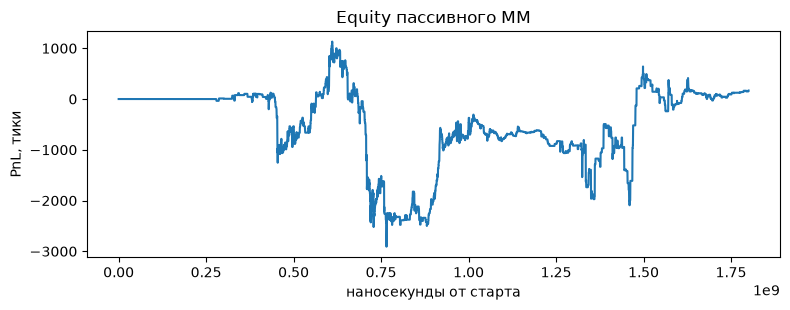

,cancel convention,fills,"net, тики",rejects
0,pessimistic: отмены позади,68,435.0,336
1,optimistic: отмены впереди,930,481.2,338


разрыв P&L между концами: 46.2 тика


In [3]:
e,r,s=run({},'MM')
print('MM: fills %d, rejects %d, pending %d, fee %.1f тиков, net %.1f тиков' % (r['fills'],r['rejects'],r['pending'],r['fee'],r['net']))
eq=np.array([(t,v) for t,v in e.equity])
fig,ax=plt.subplots(figsize=(8,3.2)); ax.plot(eq[:,0]-eq[0,0],eq[:,1])
ax.set_xlabel('наносекунды от старта'); ax.set_ylabel('PnL, тики'); ax.set_title('Equity пассивного MM')
plt.tight_layout(); plt.show()

# cancel convention: оба конца
rows=[]
for af,label in [(0.0,'pessimistic: отмены позади'),(1.0,'optimistic: отмены впереди')]:
    ee,rr,ss=run({'ahead_frac':af},'MM')
    rows.append({'cancel convention':label,'fills':rr['fills'],'net, тики':round(rr['net'],1),
                 'rejects':rr['rejects']})
CN=pd.DataFrame(rows); display(CN)
print('разрыв P&L между концами: %.1f тика' % (CN['net, тики'].max()-CN['net, тики'].min()))

## Garbage test

Берём три $T$ — в начале, середине и конце окна. Для каждого гоняем движок на чистых данных и на данных, где всё после $T$ заменено мусором (mid/bid/ask = 0, размеры = 0, трейды после $T$ = 0). Хэшируем весь лог событий с $ts\le T$: у корректного движка хэши обязаны совпасть. Рядом ставим намеренно порочную стратегию, которая использует средний mid за весь период: на порченых данных её pre-$T$ решения меняются, и тест это ловит.

`corrupt_after(T)` подменяет глобальные массивы и возвращает функцию восстановления; `pre_hash(T)` — sha256 по событиям до $T$.

In [4]:
def corrupt_after(Tcut):
    global mid,bid,ask,bsz,asz,px,amt
    saved=(mid.copy(),bid.copy(),ask.copy(),bsz.copy(),asz.copy(),px.copy(),amt.copy())
    mask=T>Tcut; rng=np.random.default_rng(99)
    mid2=mid.copy(); bid2=bid.copy(); ask2=ask.copy(); bsz2=bsz.copy(); asz2=asz.copy()
    mid2[mask]=rng.normal(0,1,mask.sum())+50000; bid2[mask]=mid2[mask]-0.05; ask2[mask]=mid2[mask]+0.05
    bsz2[mask]=0; asz2[mask]=0
    px2=px.copy(); amt2=amt.copy(); px2[tt>Tcut]=0; amt2[tt>Tcut]=0
    mid,bid,ask,bsz,asz,px,amt=mid2,bid2,ask2,bsz2,asz2,px2,amt2
    def restore():
        global mid,bid,ask,bsz,asz,px,amt
        mid,bid,ask,bsz,asz,px,amt=saved
    return restore

def pre_hash(eng,Tcut):
    rows=[(ts,k,p) for ts,k,p in eng.log if ts<=Tcut]
    return hashlib.sha256(json.dumps(rows,sort_keys=True).encode()).hexdigest()[:16]

def eng_hash(Tcut,corrupt=False,bad=False,seed=7):
    restore=corrupt_after(Tcut) if corrupt else (lambda: None)
    try:
        gmid=float(np.mean(mid)) if bad else None
        e,r,s=run({},'MM',seed=seed,bad_lookahead=bad,global_mid=gmid)
        return pre_hash(e,Tcut), r['fills']
    finally:
        restore()

rows=[]
for frac,label in [(0.1,'early (10%)'),(0.5,'middle (50%)'),(0.9,'late (90%)')]:
    Tc=int(T[0]+frac*(T[-1]-T[0]))
    hg,_=eng_hash(Tc,False,False); hc,_=eng_hash(Tc,True,False)
    hb,_=eng_hash(Tc,True,True); hb0,_=eng_hash(Tc,False,True)
    rows.append({'T':label,'good clean':hg,'good corrupt':hc,'good equal':hg==hc,
                 'bad clean':hb0,'bad corrupt':hb,'bad caught':hb0!=hb})
GT=pd.DataFrame(rows); display(GT)
print('Garbage test:', 'PASS' if GT['good equal'].all() else 'FAIL',
      '| порочная стратегия поймана в', int(GT['bad caught'].sum()), 'из 3 T')

,T,good clean,good corrupt,good equal,bad clean,bad corrupt,bad caught
0,early (10%),84a123a0c658b78a,84a123a0c658b78a,True,eaa095c4126776b4,677de35846451a3d,True
1,middle (50%),95c4e12b1d1d5b7b,95c4e12b1d1d5b7b,True,2cc3833ddbbd7188,d9806332dab4748a,True
2,late (90%),49124ccffd5a3f13,49124ccffd5a3f13,True,e7371ad1943441d6,d1c0956639978e27,True


Garbage test: PASS | порочная стратегия поймана в 3 из 3 T


## Null-strategy test

Случайная сторона, вход каждые 5 с, горизонт 1 с, выход агрессивно. Сигнала нет по построению, поэтому ожидаемый PnL равен минус cost stack: спред + две taker-комиссии. Предсказание считаем прямо по данным (entry ask/bid → exit bid/ask через $H$ шагов) и сравниваем с движком. Теряет меньше предсказания — движок где-то щедрый; зарабатывает — серьёзный баг.

In [5]:
H=10; FEE_TK=2.0*1e-4*MID_MEAN/tick
idxs=np.arange(0,n-H-1,50)
pred=np.mean([ (bid[i+H]-ask[i] + bid[i]-ask[i+H])/2 for i in idxs ])/tick - 2*FEE_TK
e,r,s=run({},'Null',seed=3,H=10)
# round-trip PnL из пар вход/выход, FIFO
q=[]; rt=[]
for a in e.aggr:
    if a['tag']=='null': q.append(a)
    elif a['tag']=='exit' and q:
        en=q.pop(0); rt.append(((a['price']-en['price'])/tick)*en['side'] - 2*FEE_TK)
rt=np.array(rt)
net_per_trade=float(rt.mean())
print('Null: входов %d, round trips %d, inv %.2f, mtm %.1f, fee %.1f' % (s.n,len(rt),e.inv,r['mtm'],r['fee']))
print('Null: net %.1f тиков, на сделку %.2f ± %.2f (SE)' % (r['net'],net_per_trade,float(rt.std(ddof=1)/np.sqrt(len(rt)))))
print('Cost-stack prediction: %.2f тика на сделку (спред + 2×%.1f taker fee)' % (pred,FEE_TK))
print('Разница engine − prediction: %.2f тика' % (net_per_trade-pred))

Null: входов 345, round trips 345, inv 0.00, mtm -5460.0, fee 80731.5
Null: net -86191.5 тиков, на сделку -249.83 ± 32.47 (SE)
Cost-stack prediction: -235.09 тика на сделку (спред + 2 taker fee 117.0)
Разница engine − prediction: -14.74 тика


## Latency sweep

Та же taker-стратегия, множитель латентности $m\in\{0,1,2,5,10\}$. PnL не может расти с латентностью: если растёт, движок использует задержку как информацию. Считаем gross PnL на round trip, его Sharpe и net после двух taker-комиссий; для устойчивости берём три сида. При $m=0$ латентности нет по построению, поэтому все сиды совпадают.

,latency mult,entries,gross/trade,se,Sharpe,net/trade
0,0,344,160.67,28.41,5.66,-73.34
1,1,1033,28.02,16.58,1.69,-205.99
2,2,1034,13.73,16.32,0.84,-220.28
3,5,1033,13.87,16.15,0.86,-220.14
4,10,1033,-13.75,15.92,-0.86,-247.75


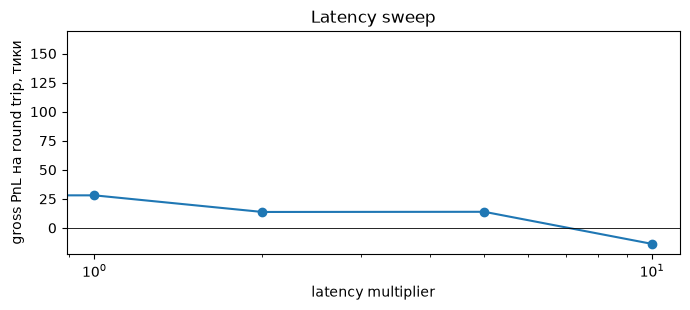

Monotone within 2 SE: True


In [6]:
def round_trip_pnls(e,fee=0.0):
    out=[]; q=[]
    for a in e.aggr:
        if a['tag']=='mom': q.append(a)
        elif a['tag']=='exit' and q:
            en=q.pop(0); out.append(((a['price']-en['price'])/tick)*en['side'] - fee)
    return np.array(out)

rows=[]
for m in [0,1,2,5,10]:
    pn=[]
    seeds=[7] if m==0 else [7,8,9]
    for seed in seeds:
        ee,rr,ss=run({'mult':m,'taker_bp':0.0},'Mom',seed=seed,H=50)
        pn.append(round_trip_pnls(ee))
    p=np.concatenate(pn)
    rows.append({'latency mult':m,'entries':len(p),'gross/trade':round(float(p.mean()),2),
                 'se':round(float(p.std(ddof=1)/np.sqrt(len(p))),2),
                 'Sharpe':round(float(p.mean()/p.std()*np.sqrt(len(p))),2),
                 'net/trade':round(float(p.mean()-2*FEE_TK),2)})
SW=pd.DataFrame(rows); display(SW)
fig,ax=plt.subplots(figsize=(7,3.2)); ax.plot(SW['latency mult'],SW['gross/trade'],'o-')
ax.axhline(0,color='k',lw=0.6); ax.set_xscale('log'); ax.set_xlabel('latency multiplier'); ax.set_ylabel('gross PnL на round trip, тики')
ax.set_title('Latency sweep'); plt.tight_layout(); plt.show()
d=SW['gross/trade'].diff().dropna()
mono=bool((d<=1.96*SW['se'].iloc[1:]).all())
print('Monotone within 2 SE:', mono)

## Bias waterfall

Восемь конфигураций одного и того же пассивного MM, cumulatively: без латентности и очереди → очередь → латентность → cancel latency → комиссии → отказы → optimistic cancel convention ($af=1$) → полностью смоделированный ($af=0.5$). Отдельного шага fill-report нет: задержка отчёта стоит во всех конфигурациях. Шаг 6 (отказы) роняет PnL, потому что отказы чаще выбивают конкурентную котировку в момент сдвига; шаг 7 поднимает, потому что $af=1$ — оптимистичный конец. Это измеренная версия waterfall на своём инструменте, а не копия стилизованного графика.

,step,"net, тики",delta
0,1 vectorised,-10358.0,0.0
1,2 + queue,2249.5,12607.5
2,3 + latency,435.0,-1814.5
3,4 + cancel latency,435.0,0.0
4,5 + fees 0.1bp,399.3,-35.7
5,6 + rejects 1%,26.7,-372.6
6,7 + optimistic cancels (af=1),556.4,529.7
7,8 fully modelled (af=0.5),556.4,0.0


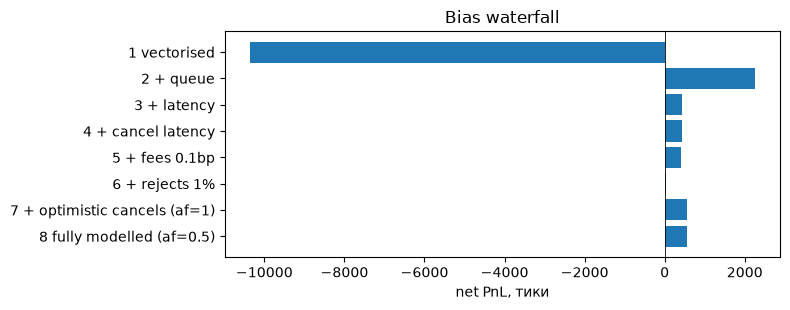

In [7]:
steps=[
 ('1 vectorised',dict(use_latency=False,use_queue=False,use_cancel_latency=False,maker_bp=0,reject_prob=0,ahead_frac=0)),
 ('2 + queue',dict(use_queue=True)),
 ('3 + latency',dict(use_latency=True,mult=1)),
 ('4 + cancel latency',dict(use_cancel_latency=True)),
 ('5 + fees 0.1bp',dict(maker_bp=0.1)),
 ('6 + rejects 1%',dict(reject_prob=0.01)),
 ('7 + optimistic cancels (af=1)',dict(ahead_frac=1.0)),
 ('8 fully modelled (af=0.5)',dict(ahead_frac=0.5)),
]
cur=dict(BASE); cur.update(use_latency=False,use_queue=False,use_cancel_latency=False,maker_bp=0,reject_prob=0,ahead_frac=0)
WF=[]; prev=None
for name,over in steps:
    cur.update(over)
    ee,rr,ss=run(dict(cur),'MM')
    net=rr['net']
    WF.append({'step':name,'net, тики':round(net,1),'delta':round(net-(prev if prev is not None else net),1)})
    prev=net
WF=pd.DataFrame(WF); display(WF)
fig,ax=plt.subplots(figsize=(8,3.2)); ax.barh(WF['step'],WF['net, тики'])
ax.axvline(0,color='k',lw=0.6); ax.set_xlabel('net PnL, тики'); ax.invert_yaxis()
ax.set_title('Bias waterfall'); plt.tight_layout(); plt.show()

## Optimism ledger

| Предпосылка | Что assumed | Направление | План |
|---|---|---|---|
| Cancel convention | отмены распределены равномерно, `ahead_frac=0.5` | ± к PnL; два конца дают разрыв | гонять оба конца, отчитываться разрывом |
| Self-impact | пассивный филл не двигает книгу | оптимистично, 0.05–0.15 PnL | добавить impact-функцию дня 13 |
| Contested depth | берём весь displayed size на touch | оптимистично | sensitivity по доле contested depth |
| Hidden liquidity | не моделируем | слегка пессимистично | оценить по своим филлам |
| Reject rate | 1% в waterfall, 0 в базе | оптимистично в бурстах | калибровать на волатильном окне |
| Aggressive fills | report-латентность не моделируется | оптимистично | добавить fill-report и для taker |
| Cancel volume | весь объём отмен интервала применяется ко всем живым ордерам | может быть пессимистично | пропорционально времени жизни |
| Fee price | fee от среднего mid, не от цены филла | мало в этом окне | считать от цены филла |
| Fee tier | maker 0 bp, taker 2 bp | оптимистично | тариф as-of с датами |
| Latency | lognormal, медианы из конфига | неизвестно | калибровать на проде, пересматривать |
| Reference data | одна версия | неизвестно | vintage-таблица |

`Ahead_frac=0.5` — не измерение, а центральная точка; оба конца показывают, сколько стоит эта неопределённость. Все числа — тики, тик $0.1$; PnL без funding и borrow.

## Вывод

- **Движок собран**: одна очередь, три часа, пять активных latency-очередей (decision и order entry объединены, ack ни на что не влияет), приоритет в момент прихода ордера, очередь впереди съедается трейдами и отменами, FILL приходит с задержкой отчёта. Стратегия получает только `(event, now)` и не имеет ссылки на replay или книгу биржи.
- **Garbage test пройден**: у корректного движка хэши pre-$T$ совпадают на всех трёх $T$ (early/middle/late); намеренно порочная стратегия со сдвигом по среднему mid за весь период ловится тоже на всех трёх. Протечек будущего в pre-$T$ решениях тест не нашёл.
- **Null test сходится**: случайная taker-стратегия теряет $-249.8$ тика на сделку (SE 32.5) против предсказания cost stack $-235.1$; разница 14.7 тика — меньше половины SE. Печатать деньги из ничего движок не умеет.
- **Latency sweep**: gross PnL на вход падает с $160.7$ тика при нулевой латентности до $-13.8$ при $10\times$; Sharpe — с 5.7 до $-0.9$, net после taker-комиссий — с $-73.3$ до $-247.8$. Кривая монотонна в пределах двух SE; m=5 и m=2 практически совпадают ($13.87$ против $13.73$ при SE 16).
- **Bias waterfall — не монотонный, и это результат, а не баг**: для пассивного MM «векторный» движок без очереди даёт $-10\,358$ тиков, а полностью смоделированный — $+556$. Наивный движок заполняет каждую сделку, включая самые неблагоприятные, поэтому для passive maker'а он **пессимистичен**; очередь и оптимистичная cancel convention отсеивают adverse fills. Знак смещения зависит от стратегии, и стилизованное «векторный ответ всегда оптимистичен» на этом инструменте не воспроизводится. Для taker-стратегии знак обратный — это видно по latency sweep.
- **Cancel convention**: два конца дают $+435.0$ (отмены позади, pessimistic) и $+481.2$ (отмены впереди, optimistic) тиков; разрыв $46.2$ — меньше эффекта латентности ($1814.5$), но больше эффекта комиссий ($35.7$) в этом окне.
- **Ограничения**: top-of-book, а не полная книга; отмены — прокси по глубине, трейды внутри спреда её завышают; self-impact не смоделирован; contested depth берётся целиком; null test — только агрессивный вход; агрессивные филлы сообщаются стратегии без report-латентности; fee считается от среднего mid; fees — допущение о VIP-тире; окно — 30 минут. Всё это лежит в optimism ledger, а не спрятано.